In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Yapay Sinir Ağları proje ortamı hazır.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Yapay Sinir Ağları proje ortamı hazır.
NumPy: 2.5.4
Pandas: 3.1.1


In [2]:
import pandas as pd
import os

dosya_yolu = "Concrete_Data.xls"

df = pd.read_excel(dosya_yolu)

print("Veri seti başarıyla yüklendi.")
print("Veri setinin boyutu:", df.shape)

print("\nDeğişken isimleri:")
print(df.columns.tolist())

print("\nİlk 5 satır:")
display(df.head())

Veri seti başarıyla yüklendi.
Veri setinin boyutu: (1030, 9)

Değişken isimleri:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']

İlk 5 satır:


C:\Users\Pc\AppData\Local\Temp\ipykernel_23776\2648800725.py:6: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(dosya_yolu)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
print("VERİ SETİ BİLGİLERİ")
print("----------------------------")

print("\nSütun bilgileri:")
df.info()

print("\nİstatistiksel özellikler:")
display(df.describe())

print("\nEksik veri kontrolü:")
print(df.isnull().sum())

VERİ SETİ BİLGİLERİ
----------------------------

Sütun bilgileri:
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64 

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225



Eksik veri kontrolü:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64


In [5]:
print("Sütun sayısı:", len(df.columns))
print("Sütun isimleri:")
print(df.columns.tolist())

Sütun sayısı: 9
Sütun isimleri:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


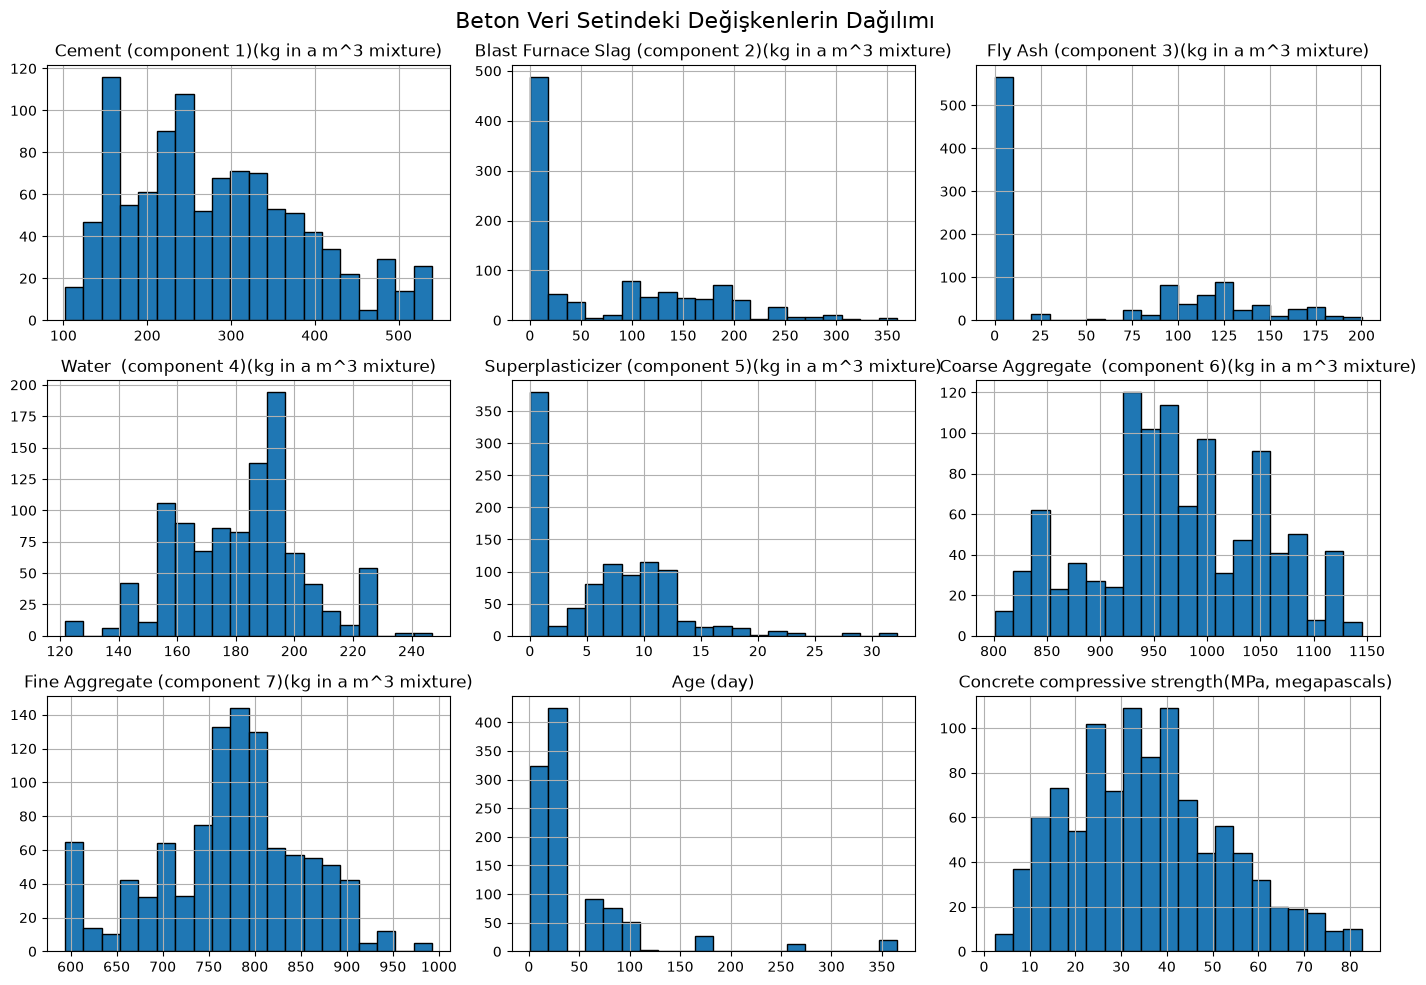

In [6]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle("Beton Veri Setindeki Değişkenlerin Dağılımı", fontsize=16)

plt.tight_layout()
plt.show()

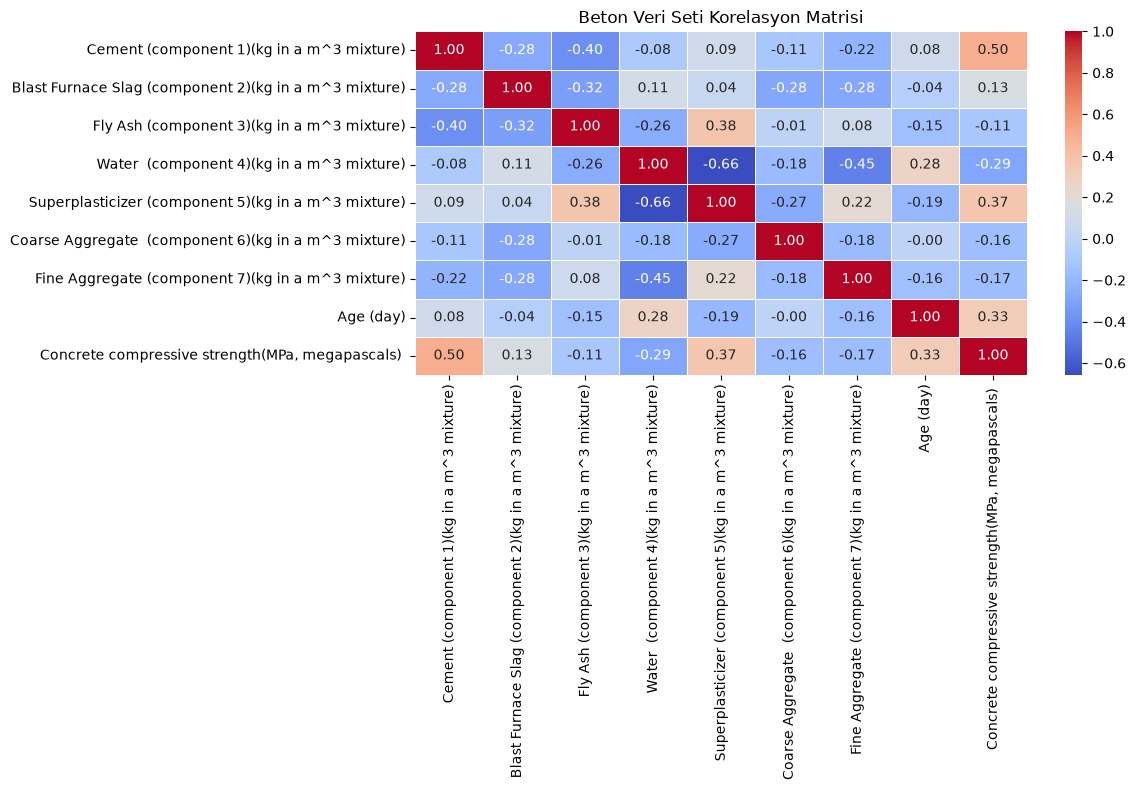

In [7]:
plt.figure(figsize=(12, 8))

korelasyon = df.corr()

sns.heatmap(
    korelasyon,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Beton Veri Seti Korelasyon Matrisi")
plt.tight_layout()
plt.show()

In [8]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("Girdi değişkenlerinin boyutu:", X.shape)
print("Çıktı değişkeninin boyutu:", y.shape)

print("\nGirdi değişkenleri:")
print(X.columns.tolist())

print("\nTahmin edilecek değişken:")
print(y.name)

Girdi değişkenlerinin boyutu: (1030, 8)
Çıktı değişkeninin boyutu: (1030,)

Girdi değişkenleri:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)']

Tahmin edilecek değişken:
Concrete compressive strength(MPa, megapascals) 


In [9]:
X = df.iloc[:, 0:8]
y = df.iloc[:, 8]

print("Girdi boyutu:", X.shape)
print("Çıktı boyutu:", y.shape)

print("Girdi değişkenleri:")
print(X.columns.tolist())

print("Tahmin edilecek değişken:")
print(y.name)

Girdi boyutu: (1030, 8)
Çıktı boyutu: (1030,)
Girdi değişkenleri:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)']
Tahmin edilecek değişken:
Concrete compressive strength(MPa, megapascals) 


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Eğitim girdi boyutu:", X_train.shape)
print("Test girdi boyutu:", X_test.shape)

print("Eğitim çıktı boyutu:", y_train.shape)
print("Test çıktı boyutu:", y_test.shape)

Eğitim girdi boyutu: (824, 8)
Test girdi boyutu: (206, 8)
Eğitim çıktı boyutu: (824,)
Test çıktı boyutu: (206,)


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Ölçeklendirme tamamlandı.")

print("\nEğitim verilerinin ortalaması:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nEğitim verilerinin standart sapması:")
print(X_train_scaled.std(axis=0).round(3))

Ölçeklendirme tamamlandı.

Eğitim verilerinin ortalaması:
[-0.  0.  0.  0. -0.  0.  0. -0.]

Eğitim verilerinin standart sapması:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
model = MLPRegressor(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=42,
    early_stopping=True
)

model.fit(X_train_scaled, y_train)

print("Yapay sinir ağı modeli eğitildi.")
print("Gizli katman sayısı: 1")
print("Nöron sayısı: 16")
print("Eğitim iterasyonu:", model.n_iter_)

Yapay sinir ağı modeli eğitildi.
Gizli katman sayısı: 1
Nöron sayısı: 16
Eğitim iterasyonu: 1638


In [13]:
y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANS SONUÇLARI")
print("----------------------------")
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("MAE:", round(mae, 3))
print("R2:", round(r2, 3))

MODEL PERFORMANS SONUÇLARI
----------------------------
MSE: 42.317
RMSE: 6.505
MAE: 5.095
R2: 0.836


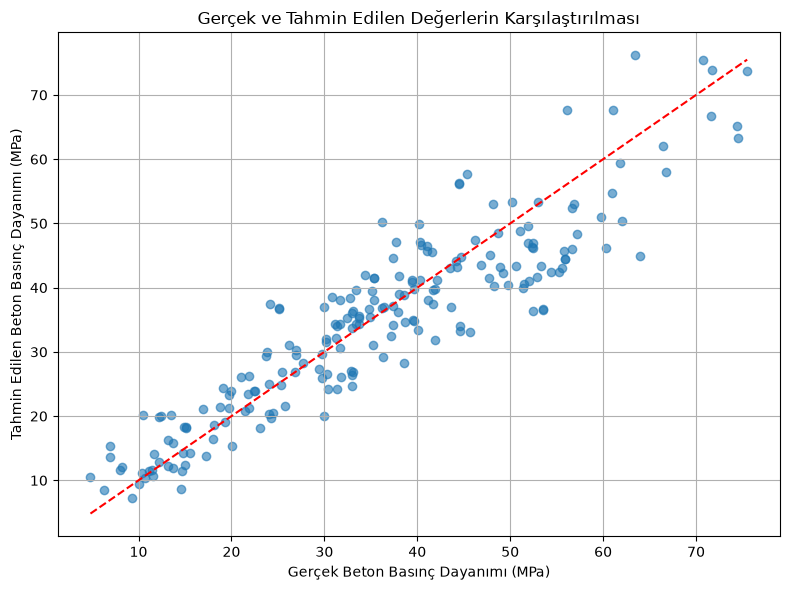

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Gerçek Beton Basınç Dayanımı (MPa)")
plt.ylabel("Tahmin Edilen Beton Basınç Dayanımı (MPa)")
plt.title("Gerçek ve Tahmin Edilen Değerlerin Karşılaştırılması")

plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
mimariler = [8, 16, 32, 64]

sonuclar = []

for noron in mimariler:

    model = MLPRegressor(
        hidden_layer_sizes=(noron,),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=2000,
        random_state=42,
        early_stopping=True
    )

    model.fit(X_train_scaled, y_train)

    tahmin = model.predict(X_test_scaled)

    rmse = np.sqrt(mean_squared_error(y_test, tahmin))
    mae = mean_absolute_error(y_test, tahmin)
    r2 = r2_score(y_test, tahmin)

    sonuclar.append({
        "Nöron Sayısı": noron,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

sonuc_df = pd.DataFrame(sonuclar)

display(sonuc_df.round(3))

,Nöron Sayısı,RMSE,MAE,R2
0,8,6.786,5.342,0.821
1,16,6.505,5.095,0.836
2,32,6.619,5.130,0.830
3,64,6.093,4.684,0.856


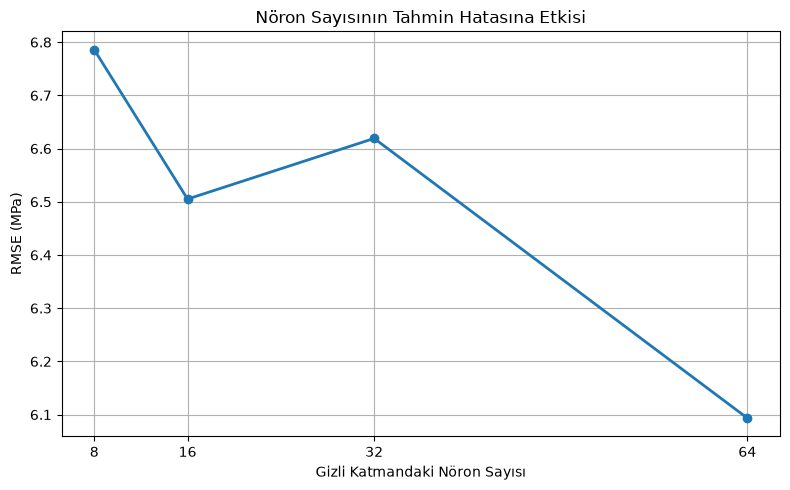

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    sonuc_df["Nöron Sayısı"],
    sonuc_df["RMSE"],
    marker="o",
    linewidth=2
)

plt.xlabel("Gizli Katmandaki Nöron Sayısı")
plt.ylabel("RMSE (MPa)")
plt.title("Nöron Sayısının Tahmin Hatasına Etkisi")
plt.xticks([8, 16, 32, 64])
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
katmanlar = [
    (16,),
    (16, 16),
    (16, 16, 16),
    (16, 16, 16, 16)
]

derinlik_sonuclari = []

for mimari in katmanlar:

    model = MLPRegressor(
        hidden_layer_sizes=mimari,
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=2000,
        random_state=42,
        early_stopping=True
    )

    model.fit(X_train_scaled, y_train)

    tahmin = model.predict(X_test_scaled)

    rmse = np.sqrt(mean_squared_error(y_test, tahmin))
    mae = mean_absolute_error(y_test, tahmin)
    r2 = r2_score(y_test, tahmin)

    derinlik_sonuclari.append({
        "Gizli Katman Sayısı": len(mimari),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

derinlik_df = pd.DataFrame(derinlik_sonuclari)

display(derinlik_df.round(3))

,Gizli Katman Sayısı,RMSE,MAE,R2
0,1,6.505,5.095,0.836
1,2,6.858,5.395,0.817
2,3,6.662,5.339,0.828
3,4,6.911,5.419,0.815


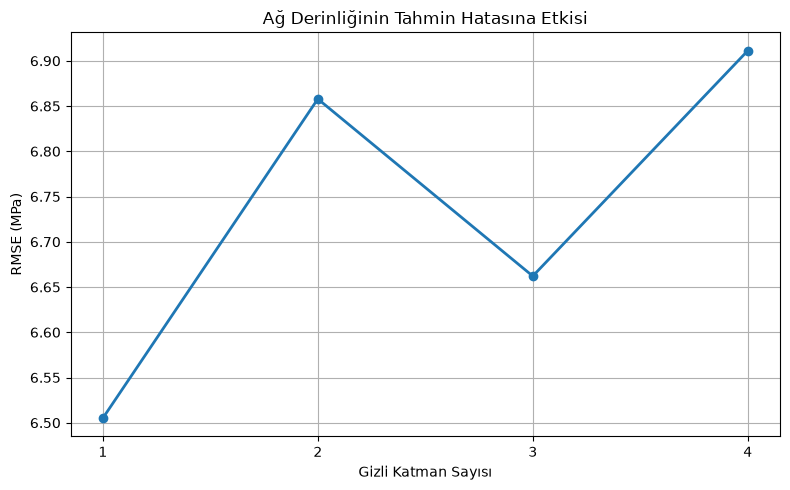

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    derinlik_df["Gizli Katman Sayısı"],
    derinlik_df["RMSE"],
    marker="o",
    linewidth=2
)

plt.xlabel("Gizli Katman Sayısı")
plt.ylabel("RMSE (MPa)")
plt.title("Ağ Derinliğinin Tahmin Hatasına Etkisi")
plt.xticks([1, 2, 3, 4])
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
tekrar_sonuclari = []

for noron in [8, 16, 32, 64]:
    for tohum in [42, 52, 62]:

        tekrar_modeli = MLPRegressor(
            hidden_layer_sizes=(noron,),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=2000,
            random_state=tohum,
            early_stopping=True
        )

        tekrar_modeli.fit(X_train_scaled, y_train)
        tahmin = tekrar_modeli.predict(X_test_scaled)

        tekrar_sonuclari.append({
            "Nöron Sayısı": noron,
            "Tohum": tohum,
            "RMSE": np.sqrt(mean_squared_error(y_test, tahmin)),
            "MAE": mean_absolute_error(y_test, tahmin),
            "R2": r2_score(y_test, tahmin)
        })

tekrar_df = pd.DataFrame(tekrar_sonuclari)

genislik_ozet = tekrar_df.groupby("Nöron Sayısı").agg(
    RMSE_Ortalama=("RMSE", "mean"),
    RMSE_Std=("RMSE", "std"),
    MAE_Ortalama=("MAE", "mean"),
    R2_Ortalama=("R2", "mean"),
    R2_Std=("R2", "std")
)

display(genislik_ozet.round(3))

,RMSE_Ortalama,RMSE_Std,MAE_Ortalama,R2_Ortalama,R2_Std
Nöron Sayısı,,,,,
8,7.282,0.620,5.783,0.793,0.036
16,6.510,0.134,5.050,0.835,0.007
32,6.769,0.302,5.272,0.822,0.016
64,6.001,0.252,4.619,0.860,0.012


In [20]:
derinlik_tekrar = []

for katman in [1, 2, 3, 4]:
    for tohum in [42, 52, 62]:

        mimari = tuple([16] * katman)

        tekrar_modeli = MLPRegressor(
            hidden_layer_sizes=mimari,
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=2000,
            random_state=tohum,
            early_stopping=True
        )

        tekrar_modeli.fit(X_train_scaled, y_train)
        tahmin = tekrar_modeli.predict(X_test_scaled)

        derinlik_tekrar.append({
            "Katman Sayısı": katman,
            "RMSE": np.sqrt(mean_squared_error(y_test, tahmin)),
            "MAE": mean_absolute_error(y_test, tahmin),
            "R2": r2_score(y_test, tahmin)
        })

derinlik_tekrar_df = pd.DataFrame(derinlik_tekrar)

derinlik_ozet = derinlik_tekrar_df.groupby("Katman Sayısı").agg(
    RMSE_Ortalama=("RMSE", "mean"),
    RMSE_Std=("RMSE", "std"),
    MAE_Ortalama=("MAE", "mean"),
    R2_Ortalama=("R2", "mean"),
    R2_Std=("R2", "std")
)

display(derinlik_ozet.round(3))

,RMSE_Ortalama,RMSE_Std,MAE_Ortalama,R2_Ortalama,R2_Std
Katman Sayısı,,,,,
1,6.510,0.134,5.050,0.835,0.007
2,6.339,0.457,4.988,0.844,0.023
3,6.137,0.459,4.899,0.853,0.022
4,6.593,0.344,5.138,0.831,0.018


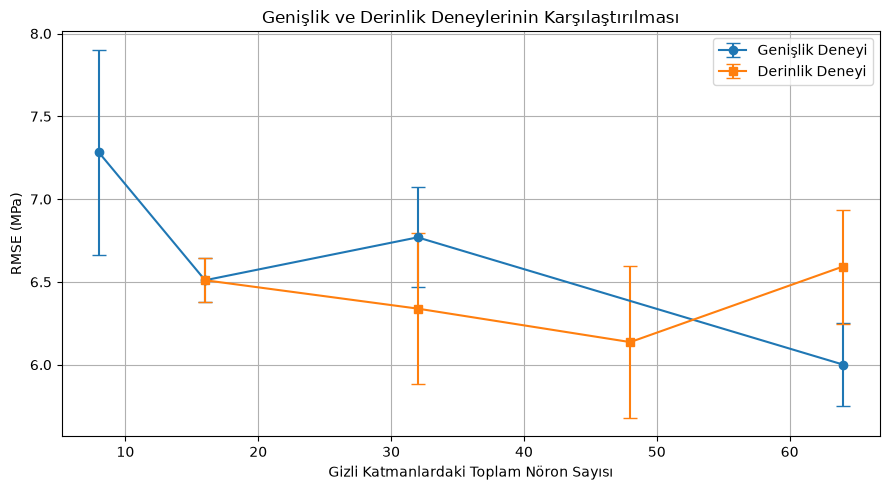

In [21]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    genislik_ozet.index,
    genislik_ozet["RMSE_Ortalama"],
    yerr=genislik_ozet["RMSE_Std"],
    marker="o",
    capsize=5,
    label="Genişlik Deneyi"
)

plt.errorbar(
    [16, 32, 48, 64],
    derinlik_ozet["RMSE_Ortalama"],
    yerr=derinlik_ozet["RMSE_Std"],
    marker="s",
    capsize=5,
    label="Derinlik Deneyi"
)

plt.xlabel("Gizli Katmanlardaki Toplam Nöron Sayısı")
plt.ylabel("RMSE (MPa)")
plt.title("Genişlik ve Derinlik Deneylerinin Karşılaştırılması")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
mimariler = {
    "1 katman - 8 nöron": (8,),
    "1 katman - 16 nöron": (16,),
    "1 katman - 32 nöron": (32,),
    "1 katman - 64 nöron": (64,),
    "2 katman - 16 nöron": (16, 16),
    "3 katman - 16 nöron": (16, 16, 16),
    "4 katman - 16 nöron": (16, 16, 16, 16)
}

parametre_sonuclari = []

for ad, mimari in mimariler.items():

    katman_boyutlari = [8] + list(mimari) + [1]

    parametre_sayisi = sum(
        katman_boyutlari[i] * katman_boyutlari[i + 1]
        + katman_boyutlari[i + 1]
        for i in range(len(katman_boyutlari) - 1)
    )

    parametre_sonuclari.append({
        "Model": ad,
        "Parametre Sayısı": parametre_sayisi
    })

parametre_df = pd.DataFrame(parametre_sonuclari)

display(parametre_df)

,Model,Parametre Sayısı
0,1 katman - 8 nöron,81
1,1 katman - 16 nöron,161
2,1 katman - 32 nöron,321
3,1 katman - 64 nöron,641
4,2 katman - 16 nöron,433
5,3 katman - 16 nöron,705
6,4 katman - 16 nöron,977


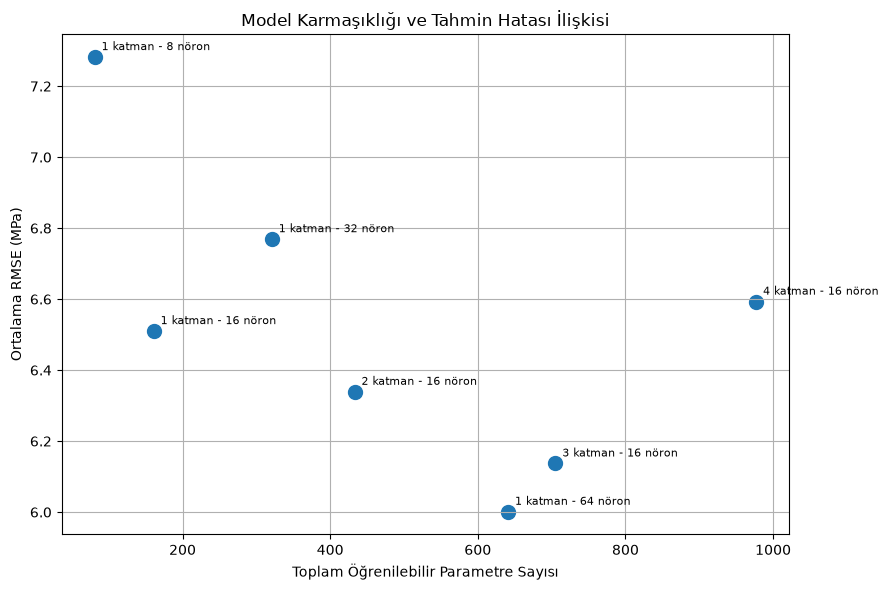

In [23]:
rmse_degerleri = [
    7.282, 6.510, 6.769, 6.001,
    6.339, 6.137, 6.593
]

plt.figure(figsize=(9, 6))

plt.scatter(
    parametre_df["Parametre Sayısı"],
    rmse_degerleri,
    s=100
)

for i, ad in enumerate(parametre_df["Model"]):
    plt.annotate(
        ad,
        (
            parametre_df["Parametre Sayısı"][i],
            rmse_degerleri[i]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Toplam Öğrenilebilir Parametre Sayısı")
plt.ylabel("Ortalama RMSE (MPa)")
plt.title("Model Karmaşıklığı ve Tahmin Hatası İlişkisi")
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
import time

sure_sonuclari = []

for ad, mimari in mimariler.items():

    baslangic = time.perf_counter()

    sure_modeli = MLPRegressor(
        hidden_layer_sizes=mimari,
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=2000,
        random_state=42,
        early_stopping=True
    )

    sure_modeli.fit(X_train_scaled, y_train)

    bitis = time.perf_counter()

    sure_sonuclari.append({
        "Model": ad,
        "Eğitim Süresi (s)": bitis - baslangic,
        "İterasyon Sayısı": sure_modeli.n_iter_
    })

sure_df = pd.DataFrame(sure_sonuclari)

display(sure_df.round(3))

,Model,Eğitim Süresi (s),İterasyon Sayısı
0,1 katman - 8 nöron,6.367,1899
1,1 katman - 16 nöron,5.205,1638
2,1 katman - 32 nöron,3.656,1152
3,1 katman - 64 nöron,4.638,1170
4,2 katman - 16 nöron,3.431,828
5,3 katman - 16 nöron,2.889,602
6,4 katman - 16 nöron,1.549,247


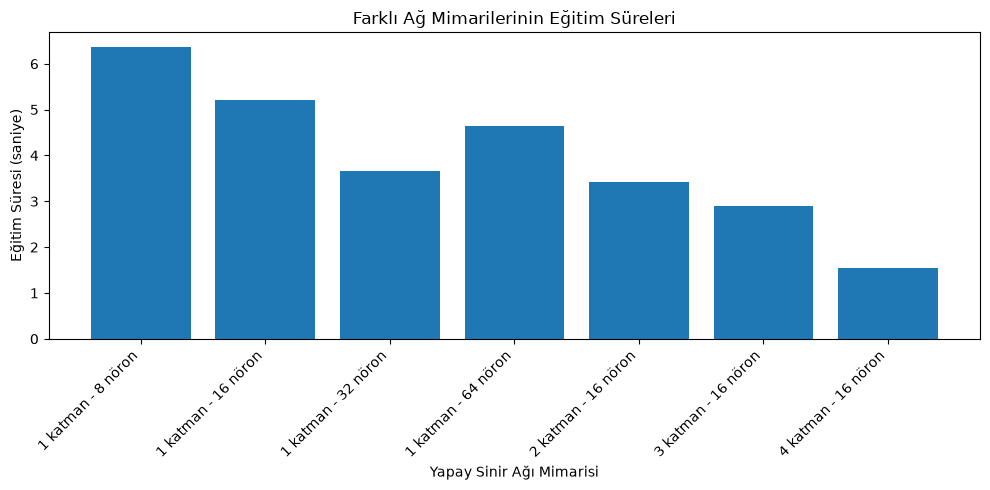

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    sure_df["Model"],
    sure_df["Eğitim Süresi (s)"]
)

plt.xlabel("Yapay Sinir Ağı Mimarisi")
plt.ylabel("Eğitim Süresi (saniye)")
plt.title("Farklı Ağ Mimarilerinin Eğitim Süreleri")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("egitim_sureleri.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
with pd.ExcelWriter("YSA_Deney_Sonuclari.xlsx") as writer:

    genislik_ozet.to_excel(writer, sheet_name="Genislik")

    derinlik_ozet.to_excel(writer, sheet_name="Derinlik")

    parametre_df.to_excel(
        writer, sheet_name="Parametreler", index=False
    )

    sure_df.to_excel(
        writer, sheet_name="Egitim_Sureleri", index=False
    )

    tekrar_df.to_excel(
        writer, sheet_name="Genislik_Tekrarlar", index=False
    )

    derinlik_tekrar_df.to_excel(
        writer, sheet_name="Derinlik_Tekrarlar", index=False
    )

print("Deney sonuçları Excel dosyasına kaydedildi.")

Deney sonuçları Excel dosyasına kaydedildi.


NameError: name 'plt' is not defined

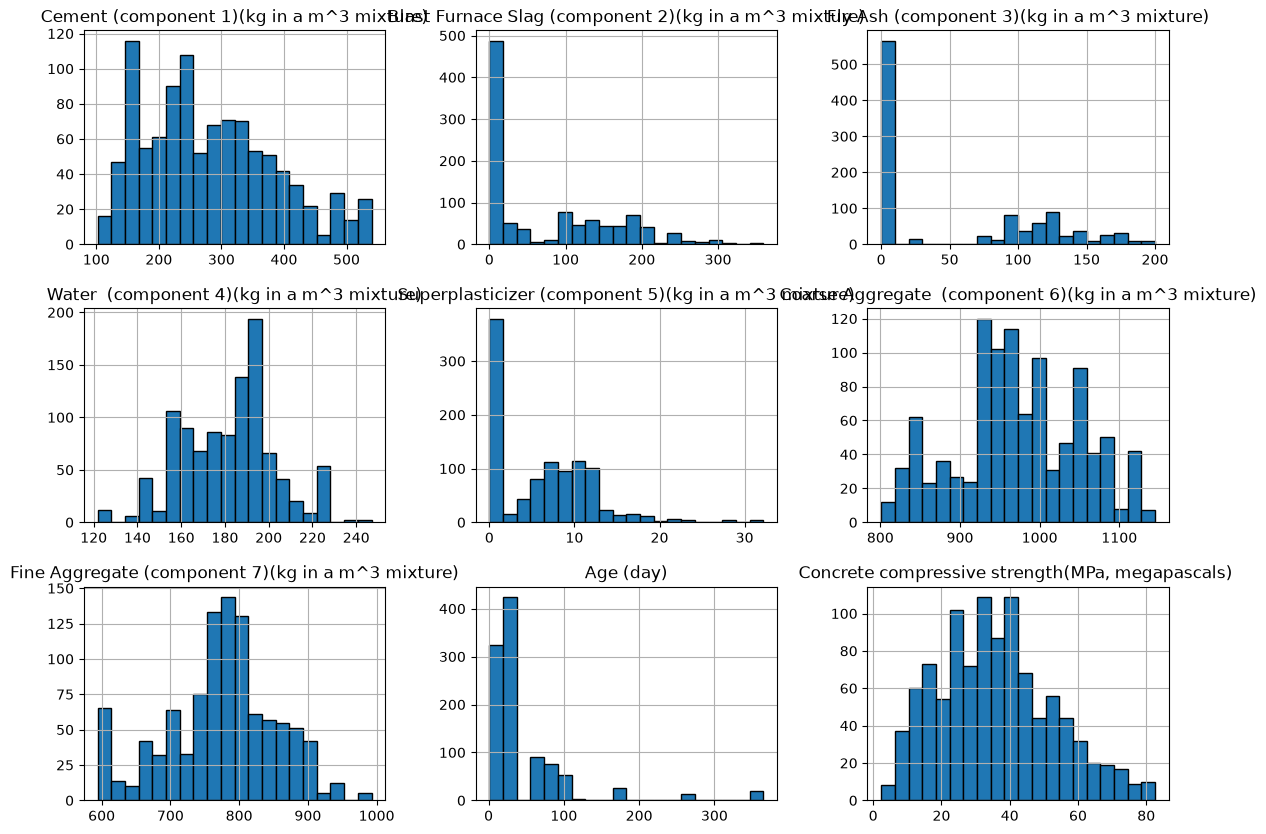

In [3]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle(
    "Beton Veri Setindeki Değişkenlerin Dağılımı",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "01_Veri_Dagilimlari.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Histogram grafikleri kaydedildi.")

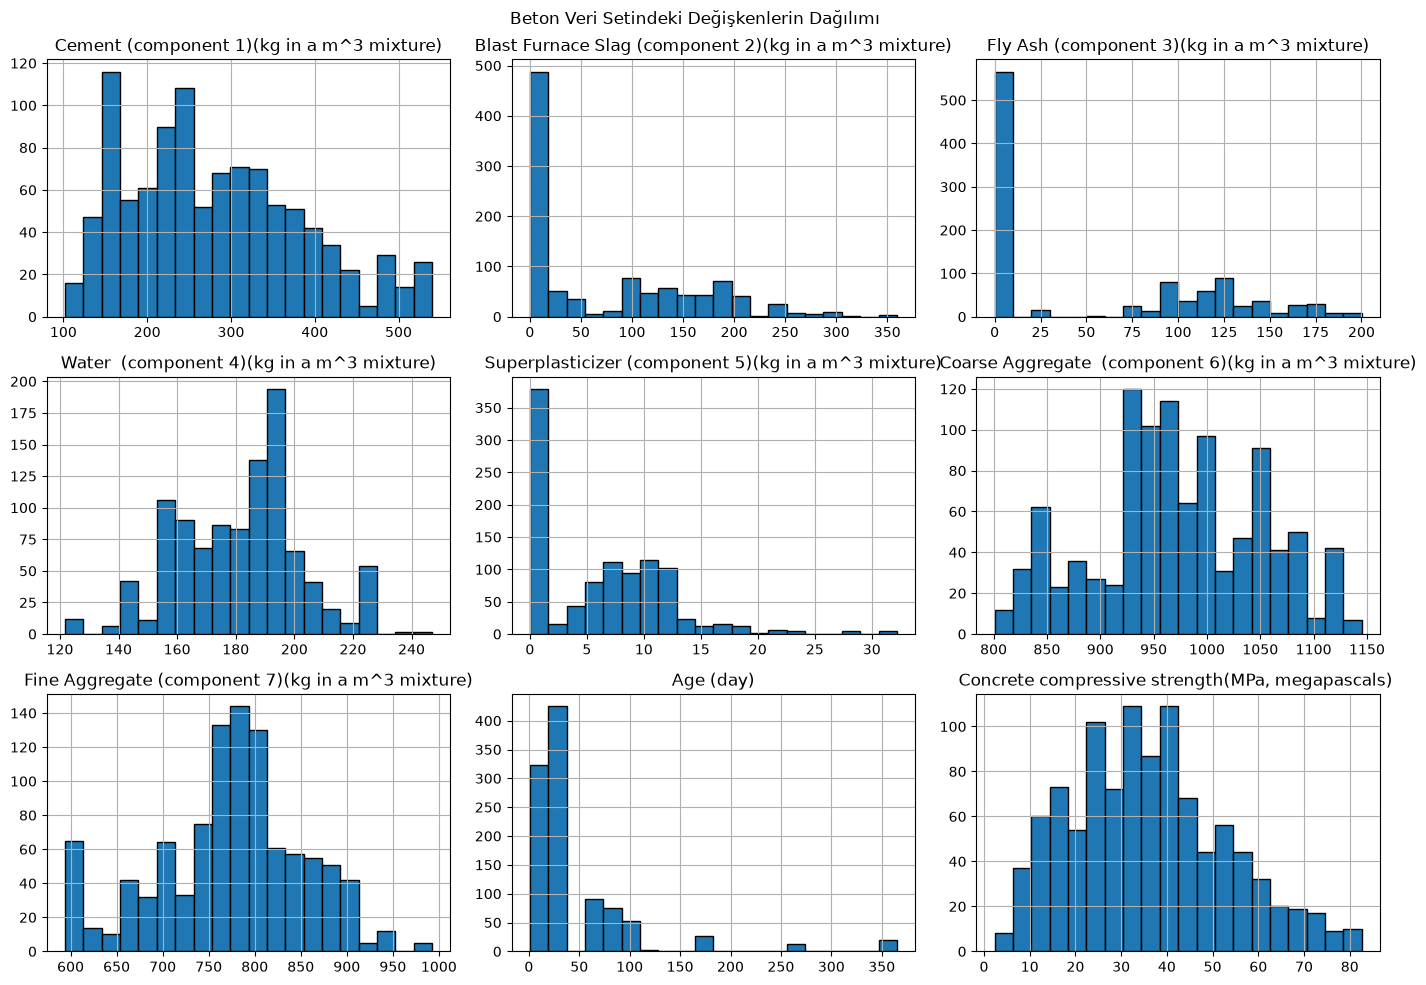

Grafik kaydedildi.


In [4]:
import matplotlib.pyplot as plt

df.hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle("Beton Veri Setindeki Değişkenlerin Dağılımı")
plt.tight_layout()

plt.savefig("01_Veri_Dagilimlari.png", dpi=300, bbox_inches="tight")
plt.show()

print("Grafik kaydedildi.")

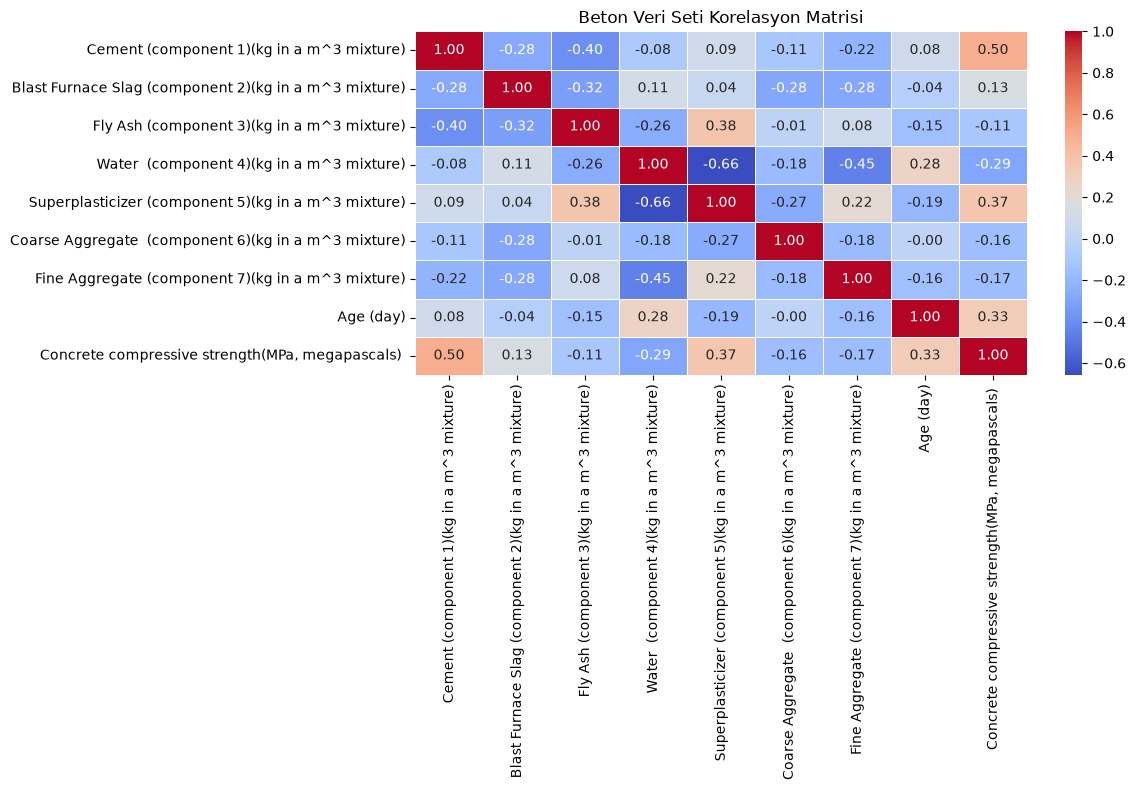

Korelasyon matrisi kaydedildi.


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Beton Veri Seti Korelasyon Matrisi")
plt.tight_layout()

plt.savefig("02_Korelasyon_Matrisi.png", dpi=300, bbox_inches="tight")
plt.show()

print("Korelasyon matrisi kaydedildi.")

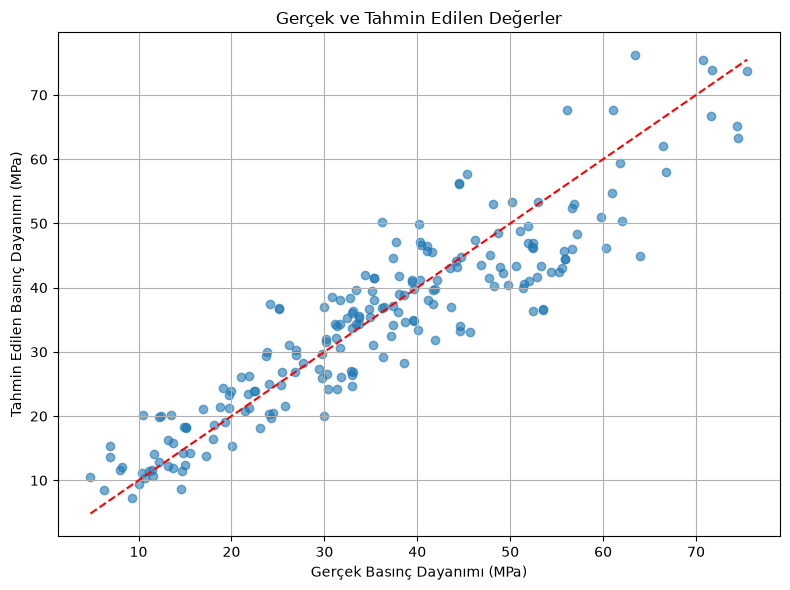

Gerçek-tahmin grafiği kaydedildi.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

X = df.iloc[:, :8]
y = df.iloc[:, 8]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = MLPRegressor(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=42,
    early_stopping=True
)

model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Gerçek Basınç Dayanımı (MPa)")
plt.ylabel("Tahmin Edilen Basınç Dayanımı (MPa)")
plt.title("Gerçek ve Tahmin Edilen Değerler")
plt.grid(True)
plt.tight_layout()

plt.savefig("03_Gercek_Tahmin.png", dpi=300, bbox_inches="tight")
plt.show()

print("Gerçek-tahmin grafiği kaydedildi.")

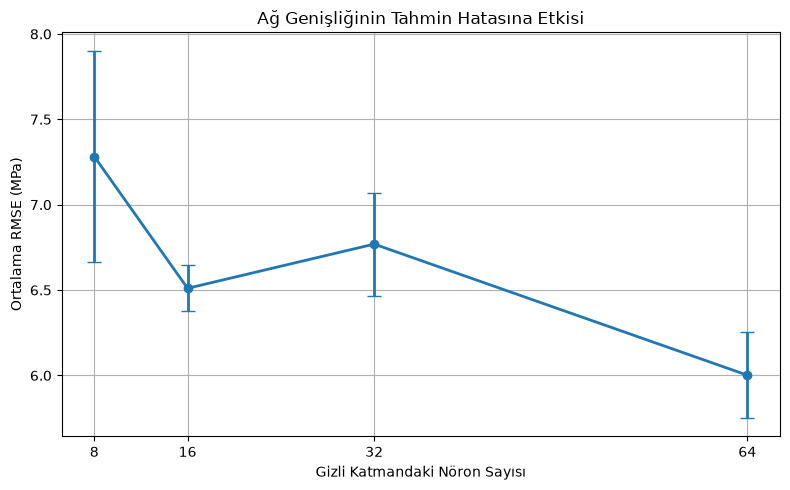

Ağ genişliği grafiği kaydedildi.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

sonuc = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Genislik"
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    sonuc["Nöron Sayısı"],
    sonuc["RMSE_Ortalama"],
    yerr=sonuc["RMSE_Std"],
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xlabel("Gizli Katmandaki Nöron Sayısı")
plt.ylabel("Ortalama RMSE (MPa)")
plt.title("Ağ Genişliğinin Tahmin Hatasına Etkisi")
plt.xticks([8, 16, 32, 64])
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "04_Ag_Genisligi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Ağ genişliği grafiği kaydedildi.")

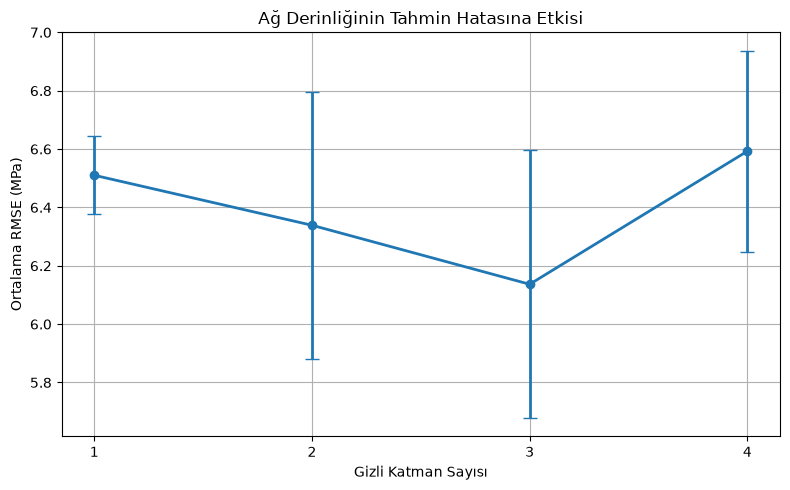

Ağ derinliği grafiği kaydedildi.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

sonuc = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Derinlik"
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    sonuc["Katman Sayısı"],
    sonuc["RMSE_Ortalama"],
    yerr=sonuc["RMSE_Std"],
    marker="o",
    capsize=5,
    linewidth=2
)

plt.xlabel("Gizli Katman Sayısı")
plt.ylabel("Ortalama RMSE (MPa)")
plt.title("Ağ Derinliğinin Tahmin Hatasına Etkisi")
plt.xticks([1, 2, 3, 4])
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "05_Ag_Derinligi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Ağ derinliği grafiği kaydedildi.")

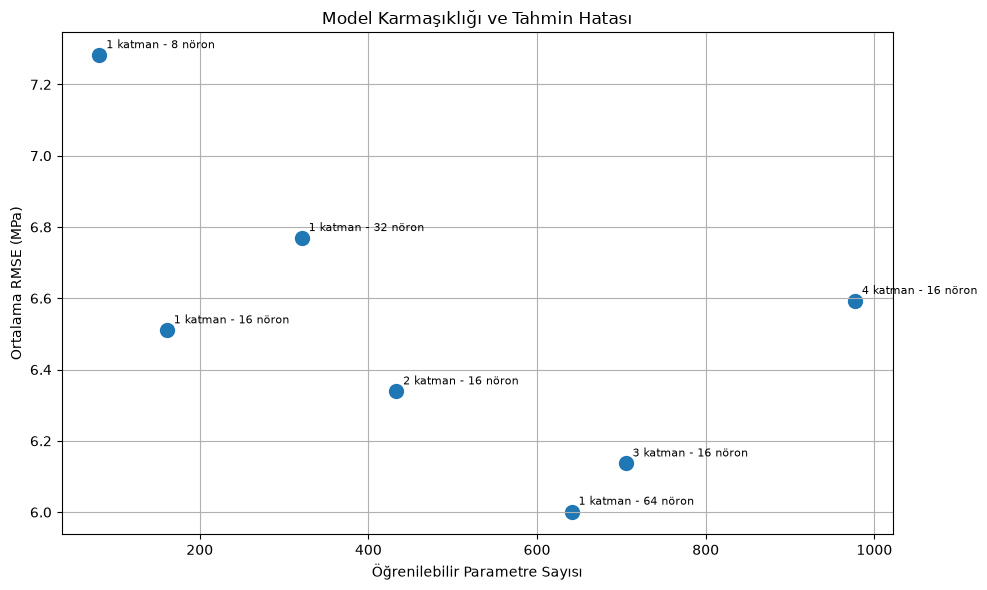

Model karmaşıklığı grafiği kaydedildi.


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

parametre = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Parametreler"
)

genislik = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Genislik"
)

derinlik = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Derinlik"
)

rmse_degerleri = (
    genislik["RMSE_Ortalama"].tolist()
    + derinlik["RMSE_Ortalama"].iloc[1:].tolist()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    parametre["Parametre Sayısı"],
    rmse_degerleri,
    s=100
)

for i, ad in enumerate(parametre["Model"]):
    plt.annotate(
        ad,
        (parametre["Parametre Sayısı"].iloc[i],
         rmse_degerleri[i]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Öğrenilebilir Parametre Sayısı")
plt.ylabel("Ortalama RMSE (MPa)")
plt.title("Model Karmaşıklığı ve Tahmin Hatası")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "06_Model_Karmasikligi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model karmaşıklığı grafiği kaydedildi.")

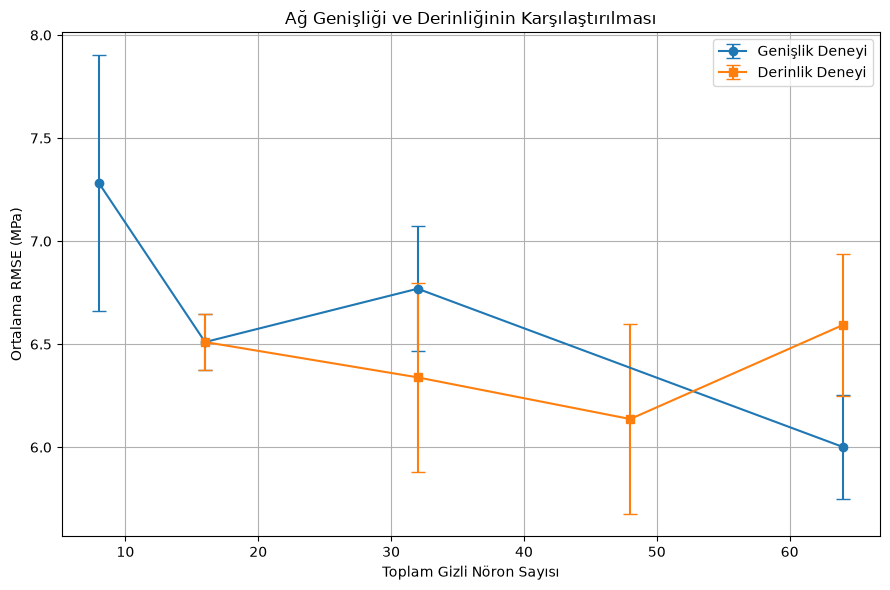

Karşılaştırma grafiği kaydedildi.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

genislik = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Genislik"
)

derinlik = pd.read_excel(
    "YSA_Deney_Sonuclari.xlsx",
    sheet_name="Derinlik"
)

plt.figure(figsize=(9, 6))

plt.errorbar(
    genislik["Nöron Sayısı"],
    genislik["RMSE_Ortalama"],
    yerr=genislik["RMSE_Std"],
    marker="o",
    capsize=5,
    label="Genişlik Deneyi"
)

plt.errorbar(
    derinlik["Katman Sayısı"] * 16,
    derinlik["RMSE_Ortalama"],
    yerr=derinlik["RMSE_Std"],
    marker="s",
    capsize=5,
    label="Derinlik Deneyi"
)

plt.xlabel("Toplam Gizli Nöron Sayısı")
plt.ylabel("Ortalama RMSE (MPa)")
plt.title("Ağ Genişliği ve Derinliğinin Karşılaştırılması")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "07_Genislik_Derinlik_Karsilastirma.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Karşılaştırma grafiği kaydedildi.")

In [11]:
print("Eğitim kaybı kayıt sayısı:", len(model.loss_curve_))

print(
    "Doğrulama puanı kaydı var mı?",
    hasattr(model, "validation_scores_")
)

Eğitim kaybı kayıt sayısı: 1638
Doğrulama puanı kaydı var mı? True


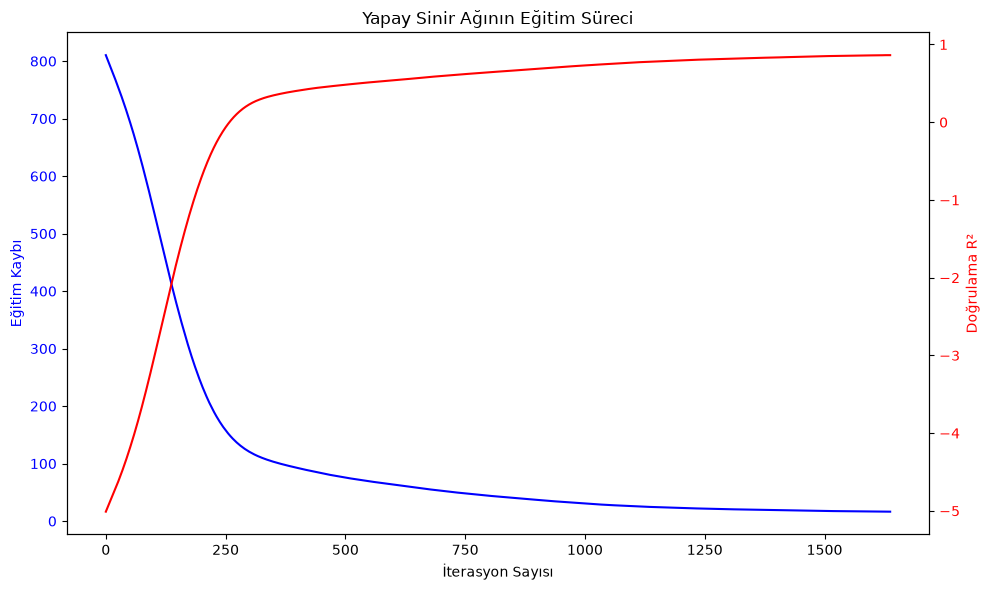

Eğitim ve doğrulama grafiği kaydedildi.


In [12]:
import matplotlib.pyplot as plt
import numpy as np

egitim_kaybi = model.loss_curve_
dogrulama_r2 = model.validation_scores_

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    egitim_kaybi,
    color="blue",
    label="Eğitim Kaybı"
)

ax1.set_xlabel("İterasyon Sayısı")
ax1.set_ylabel("Eğitim Kaybı", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()

ax2.plot(
    dogrulama_r2,
    color="red",
    label="Doğrulama R²"
)

ax2.set_ylabel("Doğrulama R²", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Yapay Sinir Ağının Eğitim Süreci")
fig.tight_layout()

plt.savefig(
    "08_Egitim_Dogrulama.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Eğitim ve doğrulama grafiği kaydedildi.")

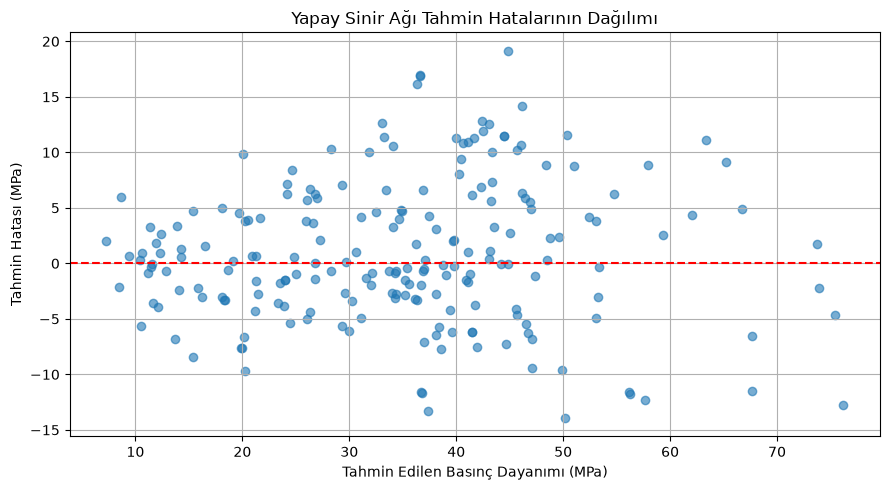

Tahmin hataları grafiği kaydedildi.


In [13]:
hatalar = y_test - y_pred

plt.figure(figsize=(9, 5))

plt.scatter(y_pred, hatalar, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Tahmin Edilen Basınç Dayanımı (MPa)")
plt.ylabel("Tahmin Hatası (MPa)")
plt.title("Yapay Sinir Ağı Tahmin Hatalarının Dağılımı")

plt.grid(True)
plt.tight_layout()

plt.savefig(
    "09_Tahmin_Hatalari.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Tahmin hataları grafiği kaydedildi.")

In [14]:
import numpy as np
import pandas as pd

hatalar = y_test - y_pred
mutlak_hatalar = np.abs(hatalar)

hata_analizi = pd.DataFrame({
    "Ölçüt": [
        "Ortalama Hata",
        "Ortalama Mutlak Hata",
        "Hata Standart Sapması",
        "En Büyük Mutlak Hata",
        "En Küçük Mutlak Hata"
    ],
    "Değer (MPa)": [
        np.mean(hatalar),
        np.mean(mutlak_hatalar),
        np.std(hatalar, ddof=1),
        np.max(mutlak_hatalar),
        np.min(mutlak_hatalar)
    ]
})

display(hata_analizi.round(3))

hata_analizi.to_excel(
    "YSA_Hata_Analizi.xlsx",
    index=False
)

print("Hata analizi Excel dosyasına kaydedildi.")

,Ölçüt,Değer (MPa)
0,Ortalama Hata,0.915
1,Ortalama Mutlak Hata,5.095
2,Hata Standart Sapması,6.456
3,En Büyük Mutlak Hata,19.156
4,En Küçük Mutlak Hata,0.012


Hata analizi Excel dosyasına kaydedildi.
